## Imports 

In [88]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.ensemble import RandomForestClassifier

## Load Dataset
- Using Scikit-learn build-in dataset 

In [2]:
iris = datasets.load_iris()


In [3]:
iris['data']

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [4]:
iris['feature_names']



['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [5]:
iris['target']

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [6]:
iris['target_names']

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

# GOAL
- Using the attributes of flowers to predict the species of flower. 
- Using Sepal length and width and Petal length and Width to predict target flowers "Setosa, Versicolor, Virginica"
- This is a multiclass classification problem 

# 1. EDA (Exploratory Data Analysis)
- Workings
    - Inspect Data Structure & Quality
    - Check class balance
    - Visualize Feature Distributions & Relationships

In [7]:
df = pd.DataFrame(iris["data"], columns=iris["feature_names"])

In [8]:
df["target"]= iris["target"]

In [9]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


- ### Basic Descriptive Statistics

In [10]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


- ### Distrubutions of Features and Target

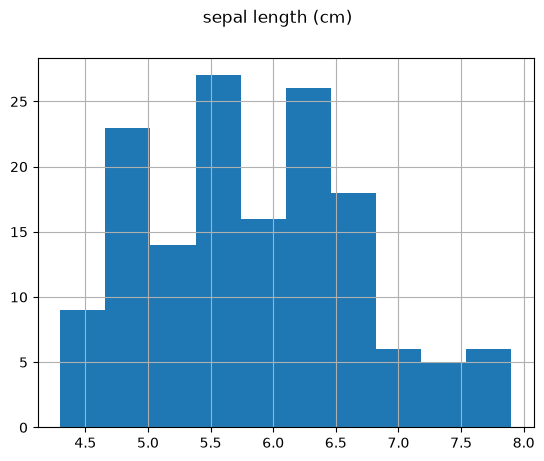

In [11]:
col = "sepal length (cm)"
df[col].hist()
plt.suptitle(col)
plt.show()

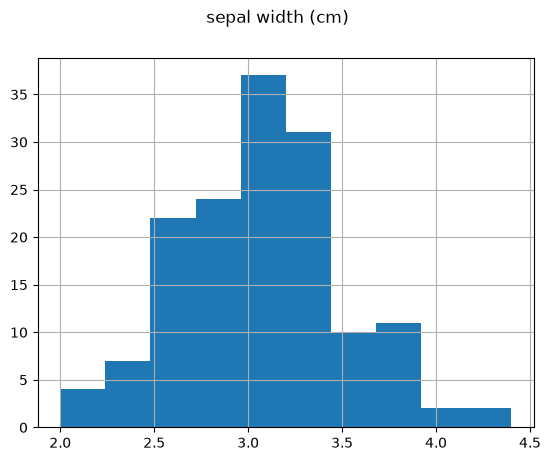

In [12]:
col = "sepal width (cm)"
df[col].hist()
plt.suptitle(col)
plt.show()

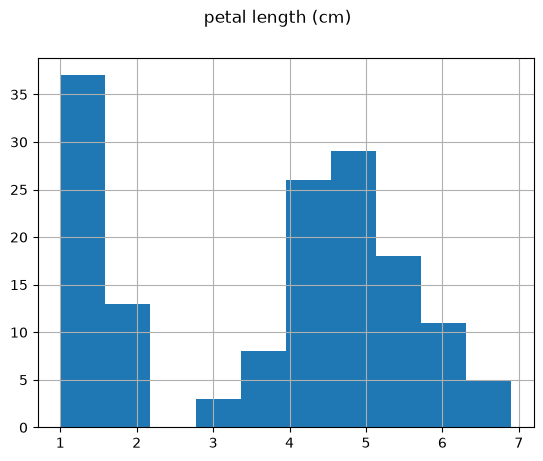

In [13]:
col = "petal length (cm)"
df[col].hist()
plt.suptitle(col)
plt.show()

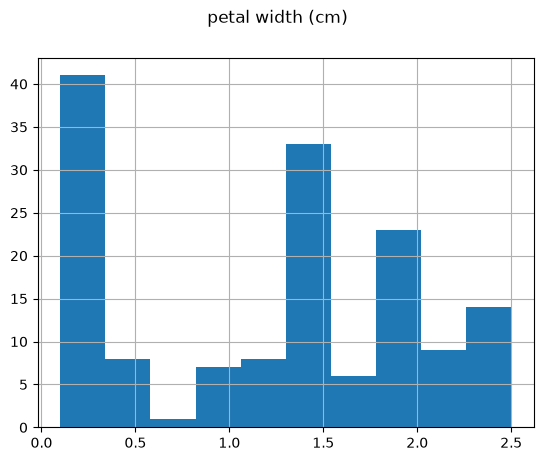

In [14]:
col = "petal width (cm)"
df[col].hist()
plt.suptitle(col)
plt.show()

- ### Relationship of the DataFeatures with the target

In [15]:
#creating new column with the species names
df['target_name']= df["target"].map({0:"setosa", 1:"versicolor",2:"virginica"})


In [16]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


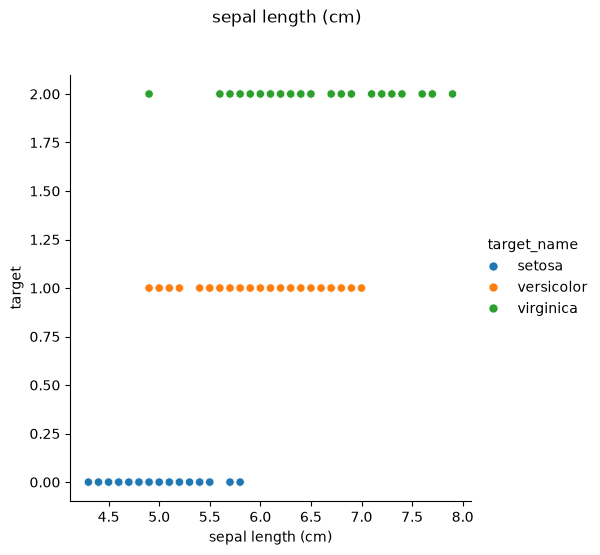

In [17]:
col= "sepal length (cm)"
sns.relplot(data=df, x= col, y= "target", hue= "target_name")
_ = plt.suptitle(col, y = 1.1)


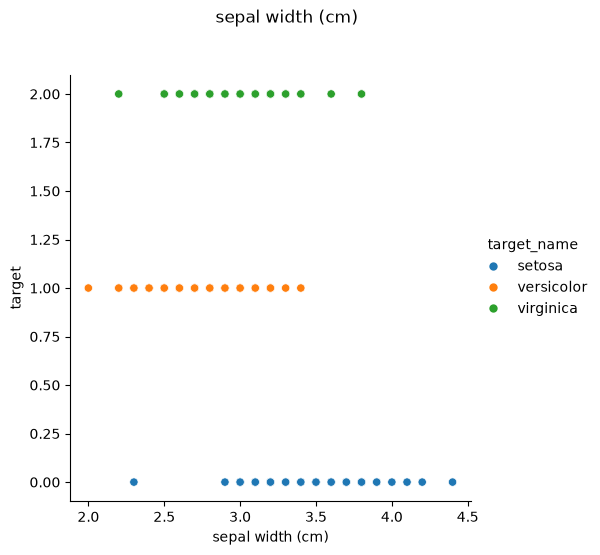

In [18]:
col= "sepal width (cm)"
sns.relplot(data=df, x= col, y= "target", hue= "target_name")
_ = plt.suptitle(col, y = 1.1)


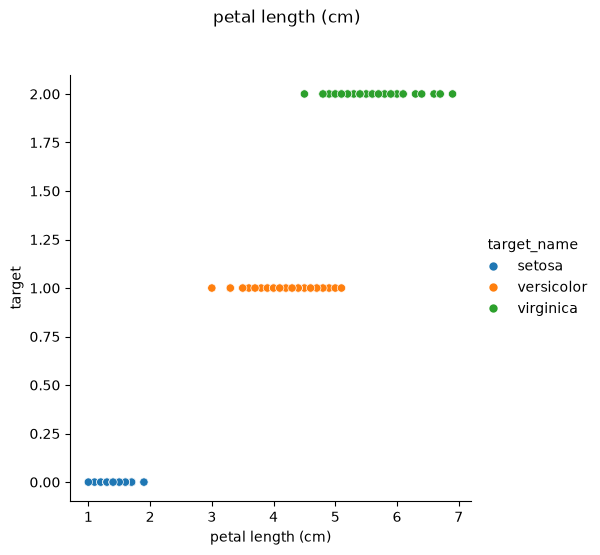

In [19]:
col= "petal length (cm)"
sns.relplot(data=df, x= col, y= "target", hue= "target_name")
_ = plt.suptitle(col, y = 1.1)


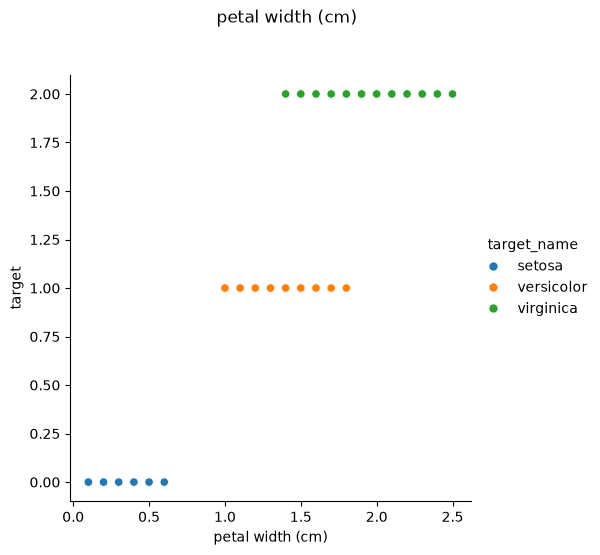

In [20]:
col= "petal width (cm)"
sns.relplot(data=df, x= col, y= "target", hue= "target_name")
_ = plt.suptitle(col, y = 1.1)


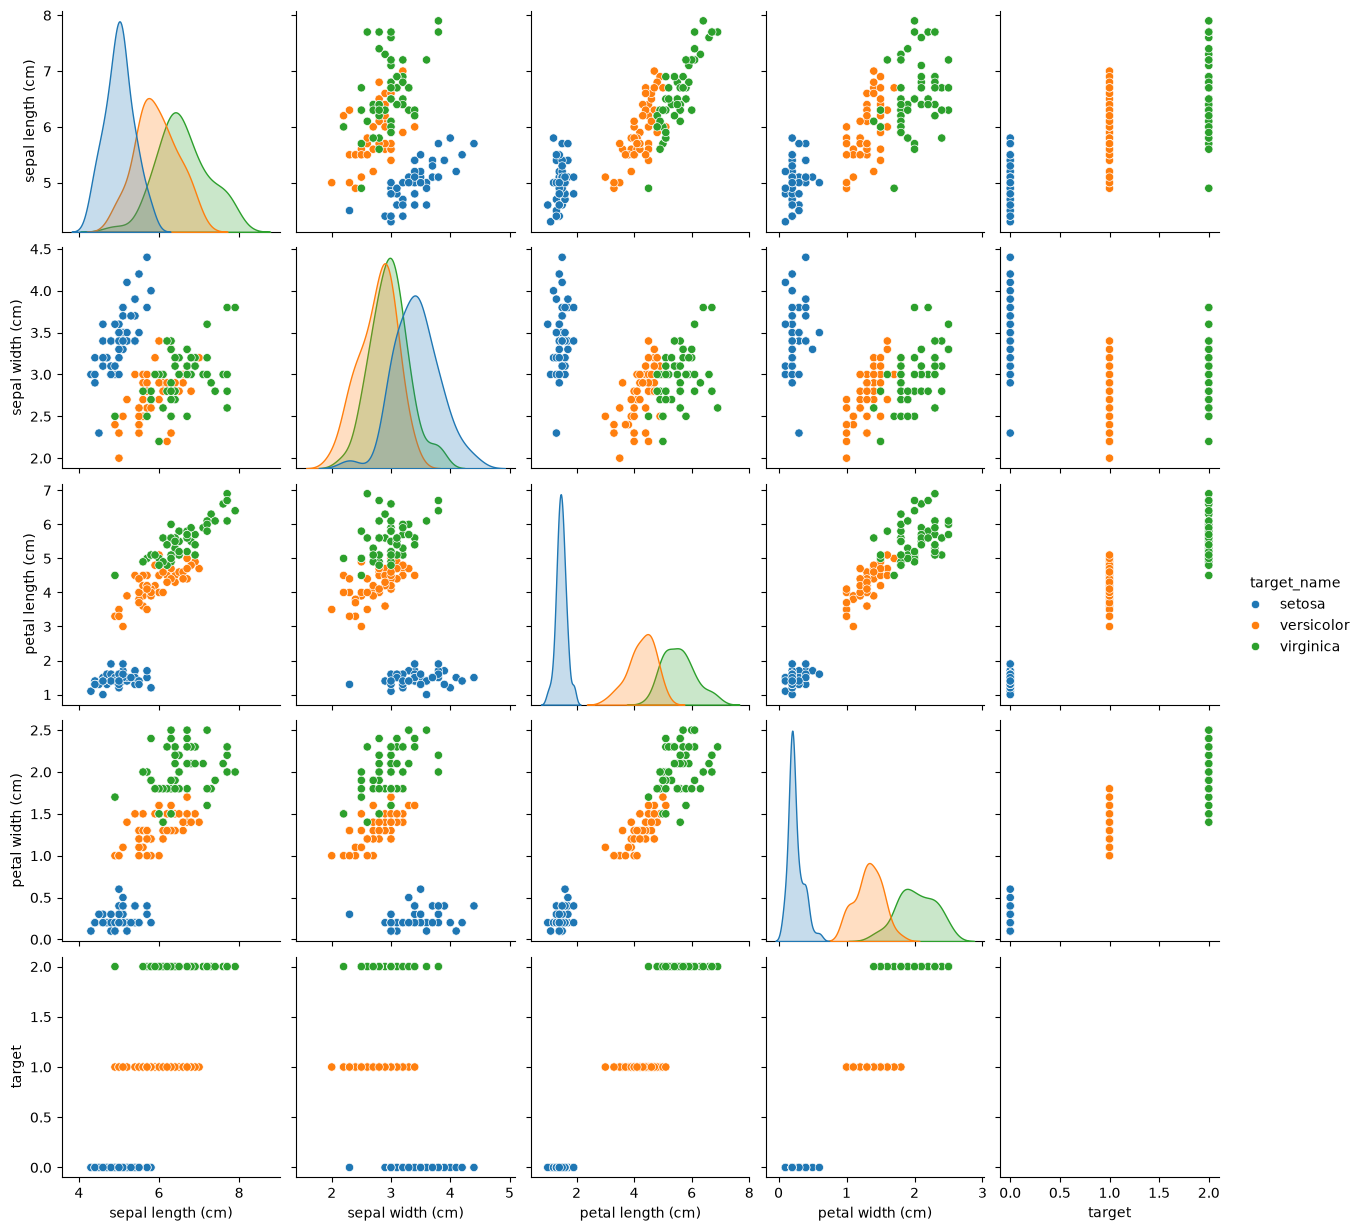

In [21]:
_ = sns.pairplot(df, hue= "target_name")

## 3.Data Preprocessing and Data Splitting.
- Workings
    - Feature and Target Separation ($X$ and $y$)
    - Label Encoding (Target Transformation)
    - Train / Test Splitting
    - Feature Scaling (Normalization / Standardization)


- ### Train test split 

In [22]:
df_train, df_test = train_test_split(df, test_size=0.25)

In [23]:
df_train.shape

(112, 6)

In [24]:
df_test.shape

(38, 6)

In [25]:
df_train.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
57,4.9,2.4,3.3,1.0,1,versicolor
99,5.7,2.8,4.1,1.3,1,versicolor
26,5.0,3.4,1.6,0.4,0,setosa
23,5.1,3.3,1.7,0.5,0,setosa
73,6.1,2.8,4.7,1.2,1,versicolor


### Prepare data from modelling 
- Involves splitting the data back into plain NumPy arrays

In [26]:
x_train= df_train.drop(columns=["target", "target_name"]).values
y_train= df_train["target"].values

- Baseline determination :
    - The baseline or the bare minimum for this model would be the model randomly guessing any one among the three targets; which would result in 0.33 or 33% accuracy since we have three evenly balanced classes.
    - Hence this model should atleast beat 33% accuray.

### Simple Manual Model
- manually deciding cutoff points for classifications

In [27]:
iris["target_names"]

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [28]:
def single_feature_prediction(petal_length):
    """Predicts the iris species given the petal length"""
    if petal_length < 2.5:
        return 0
    elif petal_length < 4.8:
        return 1
    else: 
        return 2

In [29]:
x_train[:, 2]

array([3.3, 4.1, 1.6, 1.7, 4.7, 3.5, 4.5, 5.1, 5.6, 1.7, 4. , 5.8, 6.1,
       5.7, 4.6, 3.3, 1.9, 5.1, 3.9, 1.5, 1.3, 3.5, 1.3, 4.8, 1.7, 3.7,
       5.9, 5.7, 1.5, 5.7, 1.5, 1.4, 1.5, 4.7, 1.4, 4.9, 3.8, 1.5, 4.1,
       5.1, 1.9, 4.7, 4. , 4.5, 4.2, 1.7, 4.2, 4.4, 4.5, 1.4, 5.2, 4.2,
       5.5, 4.1, 1.5, 4.4, 4.8, 5. , 1.5, 4.5, 4.3, 1.5, 1.4, 5.6, 1.4,
       1.4, 6.4, 6.7, 5. , 5.9, 6.1, 5.1, 4. , 5.1, 1.5, 3.9, 5. , 6.7,
       1. , 5.1, 1.3, 1.6, 5. , 4.6, 4.8, 4.5, 5.6, 5.6, 5.4, 4.7, 5.4,
       1.4, 1.5, 3.9, 1.3, 1.2, 5.8, 1.4, 4.5, 5.8, 1.4, 5.6, 4.9, 4.5,
       1.3, 6. , 5.5, 6. , 1.2, 5.3, 1.4, 5.1])

In [30]:
manual_y_predictions =np.array([single_feature_prediction(val) for val in x_train[: ,2]])

In [31]:
manual_model_accuracy = np.mean(manual_y_predictions == y_train)

In [32]:
print(f"Manual model accuracy {manual_model_accuracy * 100}%")

Manual model accuracy 95.53571428571429%


### 4. Logistics Regression Model

- Using a validation set to evaulate the model

In [33]:
model = LogisticRegression(max_iter=100)

In [34]:
# xt= xtrain and xv= xvalidation; similarly yt= ytrain and yv= yvalidation
xt, xv, yt, yv = train_test_split(x_train ,y_train, train_size= 0.25)

In [35]:
model.fit(xt, yt)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [36]:
y_pred= model.predict(xv)

In [37]:
np.mean(y_pred == yv)

np.float64(0.9047619047619048)

- Using cross-validation and Identifying misclassified points 

In [39]:
model = LogisticRegression()

In [45]:
accuracies = cross_val_score(model, x_train, y_train, cv =5, scoring= "accuracy")

In [46]:
np.mean(accuracies)

np.float64(0.9466403162055336)

In [47]:
y_pred= cross_val_predict(model, x_train, y_train, cv =5)

In [51]:
predicted_correctly_mask = y_pred == y_train

In [52]:
not_predicted_correctly = ~predicted_correctly_mask

In [58]:
df_predictions = df_train.copy()

In [60]:
df_predictions["correct_prediction"] = predicted_correctly_mask

In [66]:
df_predictions["prediction"]= y_pred

In [67]:
df_predictions["prediction_label"] = df_predictions["prediction"].map({0:"setosa", 1:"versicolor",2:"virginica"})

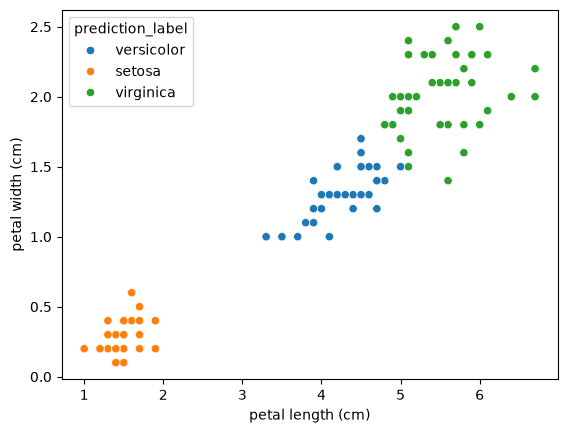

In [71]:
_ = sns.scatterplot(x="petal length (cm)", y= "petal width (cm)", hue="prediction_label" ,data= df_predictions)

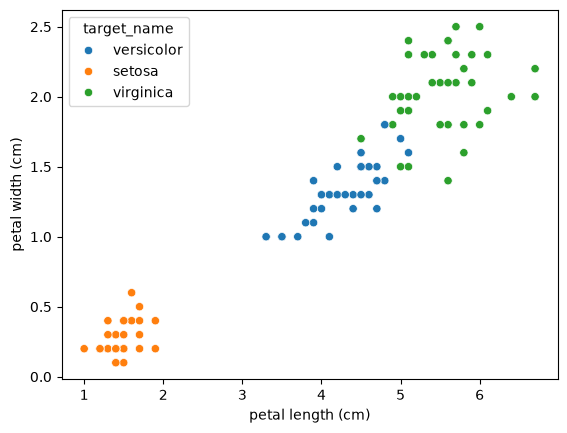

In [76]:
_ = sns.scatterplot(x="petal length (cm)", y= "petal width (cm)", hue="target_name" ,data= df_predictions)

In [86]:
def plot_incorrect_predictions(df_predictions, x_axis_feature, y_axis_feature):
    fig, axs = plt.subplots(2, 2, figsize=(10,10))
    axs = axs.flatten()
    sns.scatterplot(x= x_axis_feature, y= y_axis_feature, hue="prediction_label", data= df_predictions, ax=axs[0])
    sns.scatterplot(x= x_axis_feature, y= y_axis_feature, hue="target_name", data= df_predictions, ax=axs[1])
    sns.scatterplot(x= x_axis_feature, y= y_axis_feature, hue="correct_prediction", data= df_predictions, ax=axs[2])
    axs[3].set_visible(False)
    plt.show()

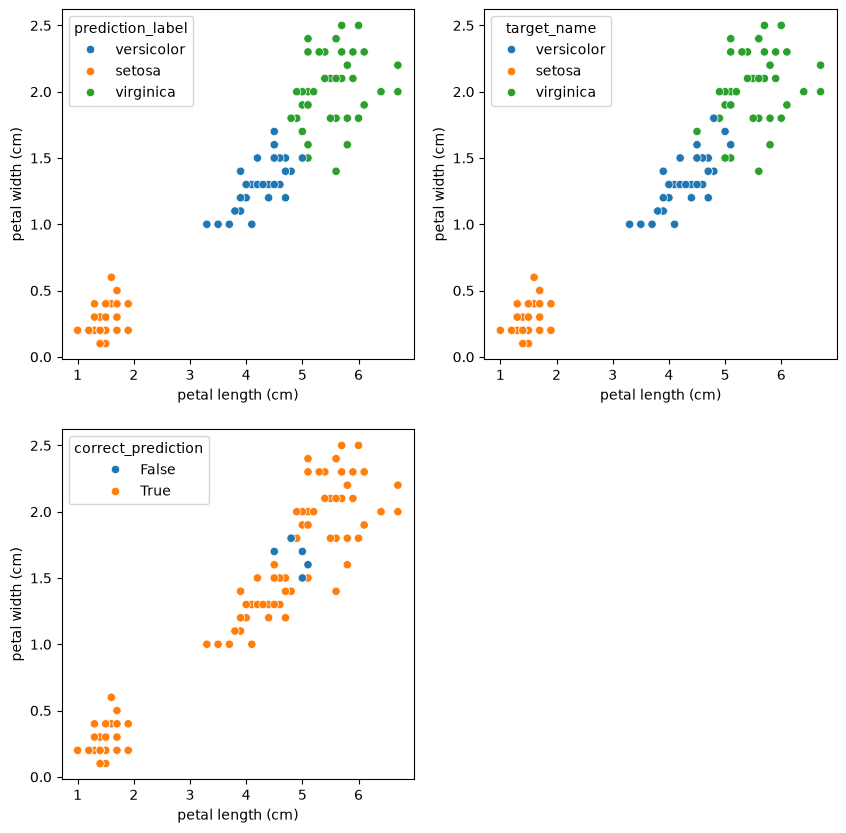

In [87]:
plot_incorrect_predictions (df_predictions, "petal length (cm)", "petal width (cm)")

### 4. Model Tuning and Test Set Accuracy


In [ ]:

model = RandomForestClassifier()